# Police Dispatch Review: Synthetic Training Data

**Week 04 team project | Tuwaiq Academy**

This notebook builds a small, reproducible police dispatch database in Neon PostgreSQL, queries it from Google Colab, and uses the returned pandas DataFrame to create three visualizations and a validated CSV export. Every record is fictional and exists only for SQL and data-analysis practice.

The workflow is: connect to Neon → create temporary relational tables → load deterministic sample records → query with SQL → analyze and visualize the result in pandas → validate and export.

> **Data and privacy:** The dataset contains no real people, locations, or incident descriptions. Do not add credentials to code or notebook output. Temporary tables belong to the open database connection and disappear when it closes.


## Project map and table relationships

The three tables model stations, patrol units, and incident reports. A station can have many units and many reported incidents. An incident can have no assigned unit or one assigned unit. Its reporting station is identified by `incident_reports.station_id`; a unit's home station does not determine which station reported an incident, because cross-station assistance is allowed.

```text
police_stations (1) ──< patrol_units
police_stations (1) ──< incident_reports >── (0..1) patrol_units
```

Primary keys identify rows; foreign keys keep references valid. Unique, required, and CHECK constraints restrict values to the agreed project contract. In particular, categories are TRAFFIC, LOST_PROPERTY, NOISE, and ASSISTANCE; statuses are OPEN, IN_PROGRESS, and CLOSED. A closed incident must have a recorded elapsed duration from 0 to 180 minutes.

## Step 1 — Connect and prepare

The support cells install/import the notebook dependencies, open one encrypted connection to Neon, and define two helpers: `query()` returns read-only SQL results as pandas DataFrames, while `action()` runs a database change and returns its affected-row count. Keep this connection open through the notebook because the tables created below are temporary and private to it.


In [4]:
%pip -q install certifi 'psycopg[binary]>=3.2,<4' pandas matplotlib seaborn

#### What this code does

Installs the Python packages needed to connect to PostgreSQL, work with tabular data, and draw charts in Colab.


In [5]:
from google.colab import userdata
import certifi
import psycopg
import pandas as pd
import matplotlib.pyplot as plt
from psycopg.connection import conninfo_to_dict
import seaborn as sns

#### What this code does

Imports Colab's secret manager, the PostgreSQL driver, pandas, Matplotlib, certificate support, and a helper for parsing the saved connection settings.


In [7]:
if 'db' in globals() and not db.closed:
  db.close()
setting = conninfo_to_dict(userdata.get("Police_weekly_Project"))
host = setting.get("host", "")
assert host.endswith(".neon.tech") and "--pooler" not in host
setting.update(sslmode="verify-full", sslrootcert=certifi.where())
db = psycopg.connect(**setting, autocommit=True, connect_timeout=20, prepare_threshold=None)
db.execute("SET statement_timeout='20s'")
print("Connected. Credentials are hidden.")

Connected. Credentials are hidden.


#### What this code does

Closes an existing connection if this setup cell is rerun, reads the connection string from Colab Secrets, checks that it uses a direct Neon endpoint, enables certificate verification, opens the database connection, and sets a query timeout. It prints a safe connection message without revealing credentials.


In [8]:
def query(sql, params=None):
  with db.transaction():
    db.execute("SET TRANSACTION READ ONLY")
    with db.execute(sql, params, prepare=True) as cur:
      if cur.description is None:
        raise ValueError("Use action() for a table change.")
      columns = [col.name for col in cur.description]
      rows = cur.fetchmany(10001)
      if len(rows) > 10000:
        raise ValueError("Bound the query result first.")
  return pd.DataFrame(rows, columns=columns)

#### What this code does

Defines `query()`, a read-only helper. It runs SQL inside a read-only transaction, fetches at most 10,001 rows to detect results that exceed the 10,000-row limit, and returns valid results as a pandas DataFrame.


In [9]:
def action(sql, params=None):
  with db.transaction():
    with db.execute(sql, params, prepare=True) as cur:
      return cur.rowcount
display(query("SELECT current_database() AS database"))

,database
0,Police_Weekly_Project


#### What this code does

Defines `action()`, the helper for SQL statements that change data or create tables. It returns the number of rows affected; unlike `query()`, it does not return a DataFrame.


## Step 2 — Create the schema

Create the parent station table before the child tables so the foreign-key references exist. The patrol-unit table refers to its home station. Incident reports refer to their reporting station and may optionally refer to an assigned patrol unit. The constraints make invalid categories, statuses, references, and closed records without a known duration impossible to store.


In [10]:
stations_table = action("""
CREATE TEMPORARY TABLE police_stations (
 station_id integer PRIMARY KEY,
 station_name text UNIQUE NOT NULL
)
""")

#### What this code does

Creates the parent `police_stations` temporary table. The station ID is its primary key, and each required station name must be unique.


In [11]:
patrol_units_table = action("""
CREATE TEMPORARY TABLE patrol_units(
    unit_id integer PRIMARY KEY,
    unit_code text UNIQUE NOT NULL,
    home_station_id integer NOT NULL REFERENCES pg_temp.police_stations(station_id)
    )
""")


#### What this code does

Creates `patrol_units`, keyed by unit ID. Unit codes must be unique, and each unit's required home-station ID must reference a station already created in the temporary schema.


In [12]:
action("""
CREATE TEMPORARY TABLE incident_reports (
    incident_id text PRIMARY KEY,
    station_id integer NOT NULL
        REFERENCES pg_temp.police_stations(station_id),
    assigned_unit_id integer
        REFERENCES pg_temp.patrol_units(unit_id),
    category text NOT NULL
        CHECK (category IN ('TRAFFIC', 'LOST_PROPERTY', 'NOISE', 'ASSISTANCE')),
    status text NOT NULL
        CHECK (status IN ('OPEN', 'IN_PROGRESS', 'CLOSED')),
    reported_at timestamp NOT NULL,
    elapsed_minutes integer
        CHECK (elapsed_minutes IS NULL OR elapsed_minutes BETWEEN 0 AND 180),
    CHECK (status <> 'CLOSED' OR elapsed_minutes IS NOT NULL)
)
""")

-1

#### What this code does

Creates `incident_reports` with a primary key and foreign keys to its reporting station and optional assigned unit. CHECK constraints restrict category, status, and elapsed-time values; a CLOSED incident must have a recorded duration.


In [13]:
try:
    action("""
        INSERT INTO pg_temp.patrol_units
            (unit_id, unit_code, home_station_id)
        VALUES (%s, %s, %s)
    """, (99, "TEST99", 99))

    raise AssertionError("Should be the unit rejected because the station doent exsist")

except psycopg.errors.ForeignKeyViolation:
    print("Test successful: The database rejected the reference to the non-existent station.")

rejected_row = query("""
    SELECT unit_id
    FROM pg_temp.patrol_units
    WHERE unit_code = %s
""", ("TEST99",))

assert rejected_row.empty
print("Additional confirmation: Unit TEST99 was not saved.")

Test successful: The database rejected the reference to the non-existent station.
Additional confirmation: Unit TEST99 was not saved.


## Step 3 — Generate and load the fixture

The deterministic generator creates four fictional stations, six patrol units, and 30 incidents dated from February 1 through March 2, 2025. The Training Station is deliberately left without units or incidents, and P06 is deliberately left without assigned incidents. Five incidents have no assigned unit. Only CLOSED incidents receive a recorded elapsed duration; OPEN and IN_PROGRESS records retain NULL because their duration is not observed.

This is a designed test fixture, not a sample of real police activity. Its balanced status counts and generated patterns must not be interpreted as operational findings.


In [14]:
from datetime import datetime, timedelta

stations = [(1, "North Station"), (2, "Central Station"), (3, "South Station"), (4, "Training Station")]
units = [(1, "P01", 1), (2, "P02", 1), (3, "P03", 2), (4, "P04", 2), (5, "P05", 3), (6, "P06", 3)]
categories = ["TRAFFIC", "LOST_PROPERTY", "NOISE", "ASSISTANCE"]
statuses = ["OPEN", "IN_PROGRESS", "CLOSED"]
incidents = []
for i in range(1, 31):
  status = statuses[(i - 1)% 3]
  incident = (
      f"I{i:03d}", (i - 1) % 3 + 1,
      None if i % 6 == 0 else (i - 1) % 5 + 1,
      categories[(i - 1) % 4], status,
      datetime(2025, 2, 1, 9) + timedelta(days=i - 1),
      10 + (i * 7) % 91 if status == "CLOSED" else None,
  )
  incidents.append(incident)
assert len(incidents) == 30

#### What this code does

Builds deterministic in-memory fixture rows: four stations, six units, and 30 incidents. The loop assigns predictable dates, categories, statuses, optional units, and durations so that every clean run produces the same dataset. The assertion checks that 30 incidents were generated.


In [15]:
with db.transaction():
  with db.cursor() as cur:
    cur.executemany(
        "INSERT INTO pg_temp.police_stations VALUES (%s, %s)", stations
    )
    cur.executemany(
        "INSERT INTO pg_temp.patrol_units VALUES (%s, %s, %s)", units
    )
    cur.executemany(
        """INSERT INTO pg_temp.incident_reports
           (incident_id, station_id, assigned_unit_id, category, status, reported_at, elapsed_minutes)
           VALUES(%s, %s, %s, %s, %s, %s, %s)
        """, incidents
    )

#### What this code does

Loads the generated rows into PostgreSQL in parent-before-child order: stations, then units, then incidents. The transaction groups the inserts so the seed data is loaded together.


In [16]:
df_stations = query(
    "SELECT station_id FROM pg_temp.police_stations"
)
df_patrols = query(
    "SELECT unit_id FROM pg_temp.patrol_units"
)
df_incidents = query(
    "SELECT incident_id FROM pg_temp.incident_reports"
)

assert len(df_stations) == 4
assert len(df_patrols) == 6
assert len(df_incidents) == 30

assert df_stations["station_id"].is_unique
assert df_patrols["unit_id"].is_unique
assert df_incidents["incident_id"].is_unique

print("PASS: Seed counts and IDs validated")

PASS: Seed counts and IDs validated



## Step 4 - SQL Review

In this step, we use SQL to retrieve and analyze incident data.

We complete eight queries using filtering, JOINs, and sorting.



### Q1 - Open Incidents
Show all OPEN incidents, ordered by time and ID.


In [17]:

sql_q1 = """
SELECT incident_id, category, reported_at
FROM pg_temp.incident_reports
WHERE status = 'OPEN'
ORDER BY reported_at, incident_id
"""

df_open = query(sql_q1)
display(df_open)

assert len(df_open) == 10
print("Q1 passed")


,incident_id,category,reported_at
0,I001,TRAFFIC,2025-02-01 09:00:00
1,I004,ASSISTANCE,2025-02-04 09:00:00
2,I007,NOISE,2025-02-07 09:00:00
3,I010,LOST_PROPERTY,2025-02-10 09:00:00
4,I013,TRAFFIC,2025-02-13 09:00:00
5,I016,ASSISTANCE,2025-02-16 09:00:00
6,I019,NOISE,2025-02-19 09:00:00
7,I022,LOST_PROPERTY,2025-02-22 09:00:00
8,I025,TRAFFIC,2025-02-25 09:00:00
9,I028,ASSISTANCE,2025-02-28 09:00:00


Q1 passed


#### What this code does

Runs Q1 to select only OPEN incidents, returns the requested columns, sorts by report time and ID, displays the result, and checks the expected 10 rows.



WHERE selects only OPEN incidents.

ORDER BY sorts the results by time, then incident ID.



### Q2 - Reporting Station
Show each incident with its reporting station using INNER JOIN.


In [18]:

sql_q2 = """
SELECT i.incident_id, s.station_name, i.category, i.status
FROM pg_temp.incident_reports i
INNER JOIN pg_temp.police_stations s
ON i.station_id = s.station_id
ORDER BY i.incident_id
"""

df_station = query(sql_q2)
display(df_station)

assert len(df_station) == 30
assert df_station["incident_id"].nunique() == 30
print("Q2 passed")


,incident_id,station_name,category,status
0,I001,North Station,TRAFFIC,OPEN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS
2,I003,South Station,NOISE,CLOSED
3,I004,North Station,ASSISTANCE,OPEN
4,I005,Central Station,TRAFFIC,IN_PROGRESS
5,I006,South Station,LOST_PROPERTY,CLOSED
6,I007,North Station,NOISE,OPEN
7,I008,Central Station,ASSISTANCE,IN_PROGRESS
8,I009,South Station,TRAFFIC,CLOSED
9,I010,North Station,LOST_PROPERTY,OPEN


Q2 passed


#### What this code does

Runs Q2 with an INNER JOIN from each incident to its reporting station. It displays the four requested columns and checks that the join still returns exactly one row for each of the 30 distinct incidents.



INNER JOIN matches each incident with its reporting station.

Each incident appears once, ordered by incident ID.



### Q3 - Assigned Patrol
Show all incidents and their assigned patrol units using LEFT JOIN.


In [19]:
sql_q3 = """
SELECT i.incident_id, u.unit_code, i.status
FROM pg_temp.incident_reports i
LEFT JOIN pg_temp.patrol_units u
ON i.assigned_unit_id = u.unit_id
ORDER BY i.incident_id
"""

df_units = query(sql_q3)
display(df_units)

assert len(df_units) == 30
assert df_units["unit_code"].isna().sum() == 5
print("Q3 passed")


,incident_id,unit_code,status
0,I001,P01,OPEN
1,I002,P02,IN_PROGRESS
2,I003,P03,CLOSED
3,I004,P04,OPEN
4,I005,P05,IN_PROGRESS
5,I006,None,CLOSED
6,I007,P02,OPEN
7,I008,P03,IN_PROGRESS
8,I009,P04,CLOSED
9,I010,P05,OPEN


Q3 passed


#### What this code does

Runs Q3 with a LEFT JOIN from incidents to their assigned units. This keeps incidents without an assigned unit in the result; the checks verify all 30 incidents remain and five unit codes are missing.



LEFT JOIN keeps all incidents, even without an assigned patrol unit.

Missing unit codes appear as NULL.

**NULL Values:**
- **Unassigned unit:** No patrol unit is assigned to the incident.
- **Unknown duration:** The handling duration is not recorded.

These represent different types of missing information. NULL does not mean zero.



### Q4 - Unused Stations
Find stations with no incidents using LEFT JOIN.


In [20]:

sql_q4 = """
SELECT s.station_name
FROM pg_temp.police_stations s
LEFT JOIN pg_temp.incident_reports i
ON s.station_id = i.station_id
WHERE i.incident_id IS NULL
ORDER BY s.station_name
"""

df_empty = query(sql_q4)
display(df_empty)

assert df_empty["station_name"].tolist() == ["Training Station"]
print("Q4 passed")


,station_name
0,Training Station


Q4 passed


#### What this code does

Runs Q4 with a LEFT JOIN from stations to incidents, then selects stations with no matching incident. The assertion checks that Training Station is the only unused station in this fixture.



LEFT JOIN keeps all stations.

IS NULL finds stations without any incidents.



### Q5 - Patrol Units

Show all patrol units and their OPEN incidents.

In [21]:

sql_q5 = """
SELECT u.unit_code, i.incident_id
FROM pg_temp.patrol_units u
LEFT JOIN pg_temp.incident_reports i
ON u.unit_id = i.assigned_unit_id
AND i.status = 'OPEN'
ORDER BY u.unit_code, i.incident_id
"""

df_unit_inventory = query(sql_q5)
display(df_unit_inventory)

assert df_unit_inventory["unit_code"].nunique() == 6
print("Q5 passed")


,unit_code,incident_id
0,P01,I001
1,P01,I016
2,P02,I007
3,P02,I022
4,P03,I013
5,P03,I028
6,P04,I004
7,P04,I019
8,P05,I010
9,P05,I025


Q5 passed


#### What this code does

Runs the first Q5 version. The OPEN-status condition is in the JOIN condition, so every patrol unit remains in the result even if it has no OPEN match. Results are ordered by unit code and incident ID.


In [22]:

sql_q5_where = """
SELECT u.unit_code, i.incident_id
FROM pg_temp.patrol_units u
LEFT JOIN pg_temp.incident_reports i
ON u.unit_id = i.assigned_unit_id
WHERE i.status = 'OPEN'
ORDER BY u.unit_code, i.incident_id
"""

df_q5_where = query(sql_q5_where)
display(df_q5_where)

print("ON units:", df_unit_inventory["unit_code"].nunique())
print("WHERE units:", df_q5_where["unit_code"].nunique())


,unit_code,incident_id
0,P01,I001
1,P01,I016
2,P02,I007
3,P02,I022
4,P03,I013
5,P03,I028
6,P04,I004
7,P04,I019
8,P05,I010
9,P05,I025


ON units: 6
WHERE units: 5


#### What this code does

Runs a comparison Q5 version with the OPEN-status condition in WHERE. It displays the filtered result and compares the number of distinct unit codes returned by the two approaches; WHERE removes unmatched units.




#### ON vs WHERE Comparison

- **ON:** Keeps all 6 patrol units, even without OPEN incidents.
- **WHERE:** Shows only units with OPEN incidents.

**Business questions:** ON shows all units and their OPEN incidents, while WHERE identifies only units with OPEN incidents.



### Q6 - February Review
Show incidents reported in February 2025.


In [23]:

sql_q6 = """
SELECT incident_id, reported_at, status
FROM pg_temp.incident_reports
WHERE reported_at >= '2025-02-01'
AND reported_at < '2025-03-01'
ORDER BY reported_at, incident_id
"""

df_february = query(sql_q6)
display(df_february)

assert len(df_february) == 28
print("Q6 passed")


,incident_id,reported_at,status
0,I001,2025-02-01 09:00:00,OPEN
1,I002,2025-02-02 09:00:00,IN_PROGRESS
2,I003,2025-02-03 09:00:00,CLOSED
3,I004,2025-02-04 09:00:00,OPEN
4,I005,2025-02-05 09:00:00,IN_PROGRESS
5,I006,2025-02-06 09:00:00,CLOSED
6,I007,2025-02-07 09:00:00,OPEN
7,I008,2025-02-08 09:00:00,IN_PROGRESS
8,I009,2025-02-09 09:00:00,CLOSED
9,I010,2025-02-10 09:00:00,OPEN


Q6 passed


#### What this code does

Runs Q6 using a half-open date range: February 1 is included and March 1 is excluded. It sorts the 2025 February results and checks the expected 28 incidents.



The date filter includes February 1 and excludes March 1.

ORDER BY sorts incidents by date, then ID.



### Q7 - Observed Duration
Show CLOSED incidents with known duration, ordered by duration and ID.


In [24]:

sql_q7 = """
SELECT incident_id, elapsed_minutes
FROM pg_temp.incident_reports
WHERE status = 'CLOSED'
AND elapsed_minutes IS NOT NULL
ORDER BY elapsed_minutes, incident_id
"""

df_duration = query(sql_q7)
display(df_duration)

assert len(df_duration) == 10
print("Q7 passed")


,incident_id,elapsed_minutes
0,I027,17
1,I015,24
2,I003,31
3,I030,38
4,I018,45
5,I006,52
6,I021,66
7,I009,73
8,I024,87
9,I012,94


Q7 passed


#### What this code does

Runs Q7 to select CLOSED incidents whose elapsed duration is known, ordering from shorter to longer duration with incident ID as a tie-breaker. The assertion checks for 10 rows.



The query selects only CLOSED incidents with a known duration.

IS NOT NULL excludes missing durations, and ORDER BY sorts from shortest to longest.



### Q8 - Chart Source
Combine incidents, stations, and patrol units for dashboard analysis.

In [25]:

sql_q8 = """
SELECT i.incident_id, s.station_name, i.category, i.status, u.unit_code,
i.reported_at, i.elapsed_minutes
FROM pg_temp.incident_reports i
INNER JOIN pg_temp.police_stations s
ON i.station_id = s.station_id
LEFT JOIN pg_temp.patrol_units u
ON i.assigned_unit_id = u.unit_id
ORDER BY i.incident_id
"""

df_dashboard = query(sql_q8)
display(df_dashboard)

assert len(df_dashboard) == 30
assert df_dashboard["incident_id"].nunique() == 30
assert df_dashboard["unit_code"].isna().sum() == 5
print("Q8 passed")


,incident_id,station_name,category,status,unit_code,reported_at,elapsed_minutes
0,I001,North Station,TRAFFIC,OPEN,P01,2025-02-01 09:00:00,NaN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS,P02,2025-02-02 09:00:00,NaN
2,I003,South Station,NOISE,CLOSED,P03,2025-02-03 09:00:00,31.0
3,I004,North Station,ASSISTANCE,OPEN,P04,2025-02-04 09:00:00,NaN
4,I005,Central Station,TRAFFIC,IN_PROGRESS,P05,2025-02-05 09:00:00,NaN
5,I006,South Station,LOST_PROPERTY,CLOSED,None,2025-02-06 09:00:00,52.0
6,I007,North Station,NOISE,OPEN,P02,2025-02-07 09:00:00,NaN
7,I008,Central Station,ASSISTANCE,IN_PROGRESS,P03,2025-02-08 09:00:00,NaN
8,I009,South Station,TRAFFIC,CLOSED,P04,2025-02-09 09:00:00,73.0
9,I010,North Station,LOST_PROPERTY,OPEN,P05,2025-02-10 09:00:00,NaN


Q8 passed


#### What this code does

Runs Q8 to create the chart-source DataFrame. It joins each incident to its reporting station and optionally to its assigned unit, then orders by incident ID. Assertions confirm one row per incident and retain all five unassigned incidents.



INNER JOIN adds each reporting station, while LEFT JOIN keeps incidents without assigned units.

Joining a station to all its patrol units would duplicate incidents. Joining by assigned_unit_id keeps one row per incident.



## Step 5 - Controlled Changes

Safely update, verify, restore, insert, and delete temporary incident records.



### 5.1 - Update Incident Status

Change incident I001 from OPEN to IN_PROGRESS using a controlled UPDATE.


In [26]:

update_sql = """
UPDATE pg_temp.incident_reports
SET status = %s
WHERE incident_id = %s
AND status = %s
"""

print("Before UPDATE:")
display(query("""
SELECT incident_id, status
FROM pg_temp.incident_reports
WHERE incident_id = %s
""", ("I001",)))


changed = action(update_sql, ("IN_PROGRESS", "I001", "OPEN"))

assert changed == 1
print("Updated rows:", changed)


Before UPDATE:


,incident_id,status
0,I001,OPEN


Updated rows: 1


#### What this code does

Previews I001's status, performs a parameterized update only if its current status is OPEN, and verifies that exactly one row changed. Parameter placeholders keep values separate from the SQL text.



The UPDATE changes I001 only when its previous status is OPEN.

Parameter binding is used to pass the values safely.

Exactly one row should be updated.



### 5.2 - Verify and Restore

Check that repeating the UPDATE changes no rows, then restore I001 to OPEN.


In [27]:

# Check status after the first update
display(query("""
SELECT incident_id, status
FROM pg_temp.incident_reports
WHERE incident_id = 'I001'
"""))

# Repeat the same update
changed_again = action(update_sql, ("IN_PROGRESS", "I001", "OPEN"))

assert changed_again == 0
print("Second update:", changed_again)

# Restore the original status
restore_sql = """
UPDATE pg_temp.incident_reports
SET status = %s
WHERE incident_id = %s
AND status = %s
"""

restored = action(restore_sql, ("OPEN", "I001", "IN_PROGRESS"))

assert restored == 1
print("Restored rows:", restored)


# Verify the final status
final_status = query("""
SELECT incident_id, status
FROM pg_temp.incident_reports
WHERE incident_id = %s
""", ("I001",))

display(final_status)
assert final_status["status"].tolist() == ["OPEN"]

print("I001 restored successfully")


,incident_id,status
0,I001,IN_PROGRESS


Second update: 0
Restored rows: 1


,incident_id,status
0,I001,OPEN


I001 restored successfully


#### What this code does

Checks that the repeated update no longer matches I001, restores the original OPEN status with a reverse parameterized update, then queries the final status and asserts that restoration succeeded.



The second UPDATE affects zero rows because I001 is no longer OPEN.

The reverse UPDATE restores I001 to its original OPEN status.

The final SELECT confirms the restored status.



### 5.3 - Insert and Delete Test Incident

Insert a temporary test incident, verify it, then delete it safely.


In [28]:

insert_sql = """
INSERT INTO pg_temp.incident_reports
(incident_id, station_id, assigned_unit_id, category,
 status, reported_at, elapsed_minutes)
VALUES (%s, %s, %s, %s, %s, %s, %s)
"""

inserted = action(insert_sql, (
    "TEST01", 1, None, "TRAFFIC",
    "OPEN", "2025-02-15 10:00:00", None
))

assert inserted == 1

test_incident = query("""
SELECT incident_id, category, status
FROM pg_temp.incident_reports
WHERE incident_id = %s
""", ("TEST01",))

display(test_incident)
assert len(test_incident) == 1

delete_sql = """
DELETE FROM pg_temp.incident_reports
WHERE incident_id = %s
"""

deleted = action(delete_sql, ("TEST01",))
assert deleted == 1

remaining = query("""
SELECT incident_id
FROM pg_temp.incident_reports
ORDER BY incident_id
""")

assert len(remaining) == 30
assert "TEST01" not in remaining["incident_id"].values

print("TEST01 deleted successfully")
print("Total incidents:", len(remaining))


,incident_id,category,status
0,TEST01,TRAFFIC,OPEN


TEST01 deleted successfully
Total incidents: 30


#### What this code does

Inserts a valid temporary incident named TEST01, selects it to confirm it exists, deletes only that ID, then verifies the table is back to 30 incidents and TEST01 is absent.



The test incident is inserted and verified using SELECT.

DELETE removes only TEST01 using WHERE.

The final check confirms that the database returns to 30 incidents.



## Step 6 - Data Visualization

Use the dashboard DataFrame to create and validate three charts.



### 6.1 - Prepare and Validate Data

Check the dashboard data before creating the charts.


In [29]:

required = ["incident_id", "station_name", "category", "status",
            "unit_code", "reported_at", "elapsed_minutes"]

assert list(df_dashboard.columns) == required
assert len(df_dashboard) == 30
assert df_dashboard["incident_id"].is_unique

df_dashboard["reported_at"] = pd.to_datetime(
    df_dashboard["reported_at"])

df_dashboard["elapsed_minutes"] = pd.to_numeric(
    df_dashboard["elapsed_minutes"], errors="raise")

print("SQL source: sql_q8")
print(sql_q8)
display(df_dashboard.head())


SQL source: sql_q8

SELECT i.incident_id, s.station_name, i.category, i.status, u.unit_code,
i.reported_at, i.elapsed_minutes
FROM pg_temp.incident_reports i
INNER JOIN pg_temp.police_stations s
ON i.station_id = s.station_id
LEFT JOIN pg_temp.patrol_units u
ON i.assigned_unit_id = u.unit_id
ORDER BY i.incident_id



,incident_id,station_name,category,status,unit_code,reported_at,elapsed_minutes
0,I001,North Station,TRAFFIC,OPEN,P01,2025-02-01 09:00:00,NaN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS,P02,2025-02-02 09:00:00,NaN
2,I003,South Station,NOISE,CLOSED,P03,2025-02-03 09:00:00,31.0
3,I004,North Station,ASSISTANCE,OPEN,P04,2025-02-04 09:00:00,NaN
4,I005,Central Station,TRAFFIC,IN_PROGRESS,P05,2025-02-05 09:00:00,NaN


#### What this code does

Checks the Q8 column names, row count, and unique incident IDs. It converts report timestamps to datetime values and elapsed durations to numeric values, then displays a preview for chart preparation.



The checks confirm the required columns, 30 incidents, and unique IDs.

Dates and durations are converted to the correct data types for analysis.



### 6.2 - Chart A: Incidents by Status

Create a vertical bar chart showing the number of incidents for each status.


SQL source: sql_q8


,incident_id,station_name,category,status,unit_code,reported_at,elapsed_minutes
0,I001,North Station,TRAFFIC,OPEN,P01,2025-02-01 09:00:00,NaN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS,P02,2025-02-02 09:00:00,NaN
2,I003,South Station,NOISE,CLOSED,P03,2025-02-03 09:00:00,31.0
3,I004,North Station,ASSISTANCE,OPEN,P04,2025-02-04 09:00:00,NaN
4,I005,Central Station,TRAFFIC,IN_PROGRESS,P05,2025-02-05 09:00:00,NaN


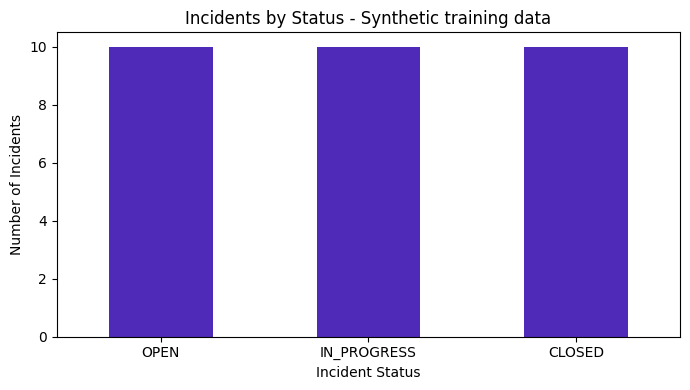

Chart A passed


In [30]:
print("SQL source: sql_q8")
display(df_dashboard.head())

status_counts = df_dashboard["status"].value_counts().reindex(
    ["OPEN", "IN_PROGRESS", "CLOSED"], fill_value=0)

ax = status_counts.plot.bar(
    color="#4F29B7", rot=0, figsize=(7, 4)
)

ax.set_title("Incidents by Status - Synthetic training data")
ax.set_xlabel("Incident Status")
ax.set_ylabel("Number of Incidents")
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig("chart_a_status.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

assert status_counts.sum() == 30
assert (status_counts == 10).all()
print("Chart A passed")


#### What this code does

Displays a preview of the SQL source and counts incidents by status in the agreed order. It draws and saves a labeled vertical bar chart, then checks that the three statuses each have 10 incidents and total 30.



**Source:** sql_q8 → df_dashboard.

**Observation:** Each status has 10 incidents, totaling 30.

**Limitation:** These balanced synthetic records do not represent real police performance.



### 6.3 - Chart B: Incident Categories

Create a horizontal bar chart showing the number of incidents in each category.


SQL source: sql_q8


,incident_id,station_name,category,status,unit_code,reported_at,elapsed_minutes
0,I001,North Station,TRAFFIC,OPEN,P01,2025-02-01 09:00:00,NaN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS,P02,2025-02-02 09:00:00,NaN
2,I003,South Station,NOISE,CLOSED,P03,2025-02-03 09:00:00,31.0
3,I004,North Station,ASSISTANCE,OPEN,P04,2025-02-04 09:00:00,NaN
4,I005,Central Station,TRAFFIC,IN_PROGRESS,P05,2025-02-05 09:00:00,NaN


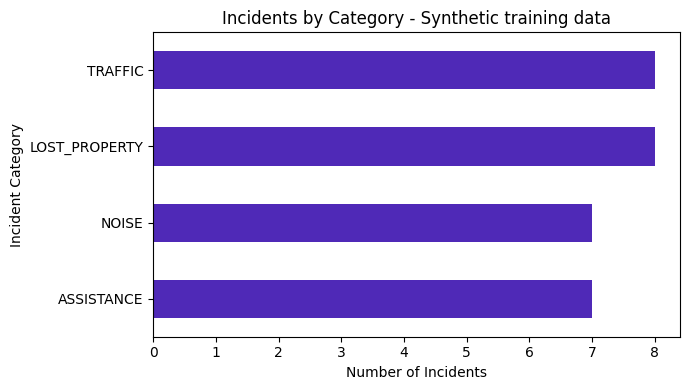

Chart B passed


In [31]:
print("SQL source: sql_q8")
display(df_dashboard.head())

category_counts = df_dashboard["category"].value_counts().reindex(
    ["TRAFFIC", "LOST_PROPERTY", "NOISE", "ASSISTANCE"], fill_value=0
).sort_values()

ax = category_counts.plot.barh(
    color="#4F29B7", figsize=(7, 4)
)

ax.set_title("Incidents by Category - Synthetic training data")
ax.set_xlabel("Number of Incidents")
ax.set_ylabel("Incident Category")
ax.set_xlim(left=0)

plt.tight_layout()
plt.savefig("chart_b_categories.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

assert category_counts.sum() == 30
assert len(category_counts) == 4

assert category_counts.to_dict() == {
    "TRAFFIC": 8,
    "LOST_PROPERTY": 8,
    "NOISE": 7,
    "ASSISTANCE": 7
}

print("Chart B passed")


#### What this code does

Displays a preview and counts records by category, ordering the counts for a horizontal bar chart. It saves the chart with labels, checks that all four categories are present, and verifies their expected synthetic counts.



**Source:** sql_q8 → df_dashboard.

**Observation:** TRAFFIC and LOST_PROPERTY have 8 incidents each; NOISE and ASSISTANCE have 7 each.

**Why a bar chart?** Categories are separate, so a line chart would suggest a false continuous trend.

**Limitation:** Synthetic counts do not reflect real incident patterns.



### 6.4 - Chart C: Recorded Handling Duration

Create a histogram showing the distribution of recorded handling durations for CLOSED incidents.


SQL source: sql_q8


,incident_id,station_name,category,status,unit_code,reported_at,elapsed_minutes
0,I001,North Station,TRAFFIC,OPEN,P01,2025-02-01 09:00:00,NaN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS,P02,2025-02-02 09:00:00,NaN
2,I003,South Station,NOISE,CLOSED,P03,2025-02-03 09:00:00,31.0
3,I004,North Station,ASSISTANCE,OPEN,P04,2025-02-04 09:00:00,NaN
4,I005,Central Station,TRAFFIC,IN_PROGRESS,P05,2025-02-05 09:00:00,NaN


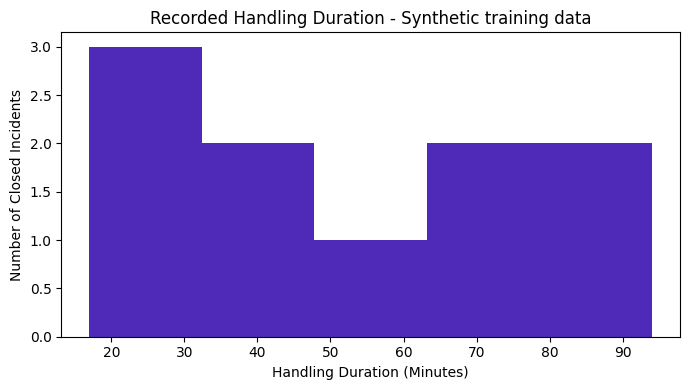

Included: 10
Excluded: 20
Chart C passed


In [32]:
print("SQL source: sql_q8")
display(df_dashboard.head())

known_closed = df_dashboard.loc[
    (df_dashboard["status"] == "CLOSED")
    & df_dashboard["elapsed_minutes"].notna(),
    "elapsed_minutes",
]

assert len(known_closed) == 10

ax = known_closed.plot.hist(
    bins=5, color="#4F29B7", figsize=(7, 4)
)

ax.set_title("Recorded Handling Duration - Synthetic training data")
ax.set_xlabel("Handling Duration (Minutes)")
ax.set_ylabel("Number of Closed Incidents")
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig("chart_c_duration.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

included = len(known_closed)
excluded = len(df_dashboard) - included

print("Included:", included)
print("Excluded:", excluded)

assert included == 10
assert excluded == 20
print("Chart C passed")


#### What this code does

Displays a preview, filters the dashboard to CLOSED incidents with known durations, and checks that 10 observations are selected. It plots and saves a five-bin histogram, reports included and excluded row counts, and confirms those counts.



**Source:** sql_q8 → df_dashboard.

**Observation:** 10 CLOSED incidents have known durations ranging from 17 to 94 minutes; 20 records are excluded.

**Limitation:** Missing durations are not treated as zero. This chart does not measure response speed or all-incident completion time.


### Download the chart images

The chart cells above save three PNG files in the current Colab session. This cell bundles them into one ZIP file and downloads it to your computer. Run it after all three charts have been created.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

chart_files = [
    Path("chart_a_status.png"),
    Path("chart_b_categories.png"),
    Path("chart_c_duration.png"),
]

missing_files = [str(path) for path in chart_files if not path.exists()]
assert not missing_files, f"Create all three charts first. Missing: {missing_files}"

zip_filename = "police_dispatch_charts.zip"
with ZipFile(zip_filename, "w") as zip_file:
    for path in chart_files:
        zip_file.write(path, arcname=path.name)

print("Saved chart images:", [path.name for path in chart_files])
files.download(zip_filename)


## Interpretation checkpoint

Before presenting the results, connect each observation to the exact query or chart that produced it. Describe what these 30 synthetic records show, then state what the fixture cannot establish. In particular, it cannot support conclusions about real response performance, station effectiveness, or incident patterns in a community.


## Step 7 - CSV Export & Validation

Export the final dashboard data into a CSV file.

Validate the exported file by checking its columns, row count,
unique incident IDs, sorting order, and data consistency.

### Export contract

The CSV contains only `incident_id`, `station_name`, `category`, and `status`, with one row per incident, sorted by ID. It is the full 30-row fixture rather than a limited preview. The reload checks below compare the exported columns, row count, unique IDs, order, and source records.


In [33]:
import pandas as pd

# Required CSV columns
required_columns = [
    "incident_id",
    "station_name",
    "category",
    "status"
]

# Check source DataFrame
assert "df_dashboard" in globals()
assert all(col in df_dashboard.columns for col in required_columns)

# Select required columns
df_export = df_dashboard[required_columns].copy()

# Sort by incident_id
df_export = df_export.sort_values(
    by="incident_id"
).reset_index(drop=True)

print("Source data prepared successfully")

display(df_export.head(10))

Source data prepared successfully


,incident_id,station_name,category,status
0,I001,North Station,TRAFFIC,OPEN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS
2,I003,South Station,NOISE,CLOSED
3,I004,North Station,ASSISTANCE,OPEN
4,I005,Central Station,TRAFFIC,IN_PROGRESS
5,I006,South Station,LOST_PROPERTY,CLOSED
6,I007,North Station,NOISE,OPEN
7,I008,Central Station,ASSISTANCE,IN_PROGRESS
8,I009,South Station,TRAFFIC,CLOSED
9,I010,North Station,LOST_PROPERTY,OPEN


#### What this code does

Defines the four columns to export, verifies they exist in the dashboard data, selects only those columns, sorts by incident ID, resets the index, and previews the prepared export DataFrame.


In [34]:
# Export CSV

csv_filename = "police_dispatch_review.csv"

df_export.to_csv(
    csv_filename,
    index=False
)

print("CSV Export Successful!")
print("File name:", csv_filename)

CSV Export Successful!
File name: police_dispatch_review.csv


#### What this code does

Writes the prepared four-column DataFrame to `police_dispatch_review.csv` without adding a pandas index, then reports the filename.


In [35]:
# Reload exported CSV

df_check = pd.read_csv(csv_filename)

print("CSV file loaded successfully")

display(df_check.head(10))

CSV file loaded successfully


,incident_id,station_name,category,status
0,I001,North Station,TRAFFIC,OPEN
1,I002,Central Station,LOST_PROPERTY,IN_PROGRESS
2,I003,South Station,NOISE,CLOSED
3,I004,North Station,ASSISTANCE,OPEN
4,I005,Central Station,TRAFFIC,IN_PROGRESS
5,I006,South Station,LOST_PROPERTY,CLOSED
6,I007,North Station,NOISE,OPEN
7,I008,Central Station,ASSISTANCE,IN_PROGRESS
8,I009,South Station,TRAFFIC,CLOSED
9,I010,North Station,LOST_PROPERTY,OPEN


#### What this code does

Reloads the saved CSV into a new DataFrame and displays its first ten rows so the exported file can be checked independently of the in-memory source.


In [36]:
# CSV Validation

checks = {
    "Correct columns": (
        list(df_check.columns) == required_columns
    ),

    "Exactly 30 rows": (
        len(df_check) == 30
    ),

    "Exactly 4 columns": (
        df_check.shape[1] == 4
    ),

    "Unique incident IDs": (
        df_check["incident_id"].is_unique
    ),

    "Sorted by incident_id": (
        df_check["incident_id"].is_monotonic_increasing
    ),

    "No missing values": (
        not df_check.isnull().any().any()
    ),

    "Same incident IDs as source": (
        set(df_check["incident_id"])
        == set(df_export["incident_id"])
    )
}

for name, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {name}")

assert all(checks.values()), "CSV validation failed!"

# Compare complete exported data with source
pd.testing.assert_frame_equal(
    df_check,
    df_export,
    check_dtype=False
)

print("\nALL CSV VALIDATION CHECKS PASSED!")

PASS: Correct columns
PASS: Exactly 30 rows
PASS: Exactly 4 columns
PASS: Unique incident IDs
PASS: Sorted by incident_id
PASS: No missing values
PASS: Same incident IDs as source

ALL CSV VALIDATION CHECKS PASSED!


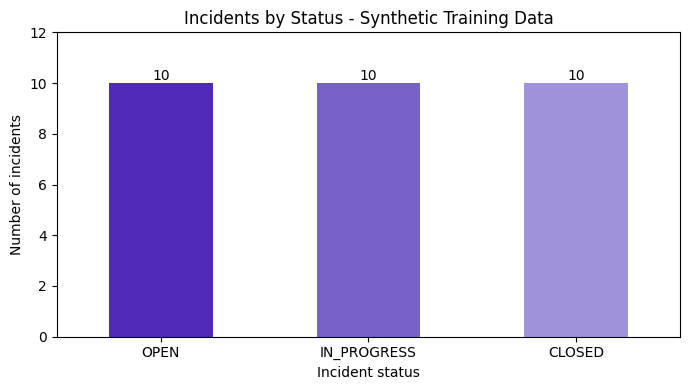

Chart A passed


In [37]:

status_counts = (
    df_dashboard["status"]
    .value_counts()
    .reindex(["OPEN", "IN_PROGRESS", "CLOSED"], fill_value=0)
)


ax = status_counts.plot.bar(
    color=["#4F29B7", "#7760C8", "#A091DD"],
    rot=0,
    figsize=(7, 4)
)

ax.set_title("Incidents by Status - Synthetic Training Data")
ax.set_xlabel("Incident status")
ax.set_ylabel("Number of incidents")
ax.set_ylim(0, max(status_counts.max() + 2, 1))


for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("chart_a_status.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()


assert status_counts.sum() == 30
assert (status_counts == 10).all()
print("Chart A passed")

#### What this code does

Runs named validation checks on the reloaded CSV: required columns, 30 rows, four columns, unique and sorted IDs, no missing values, and matching incident IDs. It then compares all exported values to the prepared DataFrame and stops with an error if a check fails.


In [38]:
# Final CSV Report

print("========== CSV FINAL REPORT ==========")

print("File:", csv_filename)
print("Rows:", len(df_check))
print("Columns:", len(df_check.columns))
print("Unique IDs:", df_check["incident_id"].nunique())
print("Sorted:", df_check["incident_id"].is_monotonic_increasing)

print("\nColumn names:")
print(df_check.columns.tolist())

print("\nFinal validation:")
print("SUCCESS")

========== CSV FINAL REPORT ==========
File: police_dispatch_review.csv
Rows: 30
Columns: 4
Unique IDs: 30
Sorted: True

Column names:
['incident_id', 'station_name', 'category', 'status']

Final validation:
SUCCESS


#### What this code does

Prints a concise report of the CSV filename, dimensions, unique IDs, sorting result, column names, and final validation status.


In [40]:
from google.colab import files

files.download(csv_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### What this code does

Uses Google Colab's file-download interface to download the validated CSV to the user's computer.


## Provenance, findings, and limitations

- **Provenance:** All records are synthetic and generated deterministically for this training exercise.
- **Grain and coverage:** One dashboard/CSV row represents one incident. The fixture covers February 1 through March 2, 2025, and the final report uses all 30 records rather than a LIMIT preview.
- **Status:** The fixture contains 10 incidents in each status by design. These counts describe only this dataset.
- **Categories:** TRAFFIC and LOST_PROPERTY each have 8 records; NOISE and ASSISTANCE each have 7. A bar chart is suitable because categories are discrete; connecting them as a time-series line would imply an ordering or continuity that does not exist.
- **Recorded duration:** The histogram includes 10 CLOSED incidents with known durations and excludes 20 records whose duration is unknown or not applicable. NULL is missing information, not zero. The measure is recorded total handling duration for closed incidents, not dispatch response time or completion time for every incident.
- **Interpretation limit:** The generator deliberately couples station assignment and status. No station effect, real-world performance, deployment recommendation, or causal conclusion can be inferred from these data.

The notebook should be rerun from a fresh Colab runtime to reproduce the temporary tables, query results, figures, and CSV. Confirm the test incident is absent and I001 has been restored to OPEN before presenting the baseline results.
